# Kingdomino - kNN klassifikation

I denne notebook bygger og tester vi en kNN-model, som skal genkende terræntypen på felterne i Kingdomino.

Vi går igennem processen trin for trin:

1. Indlæs data
2. Lav HSV-værdier for hvert felt
3. Standardiser data
4. Prøv forskellige K-værdier
5. Vælg K
6. Træn modellen
7. Test modellen
8. Vis resultatet i en confusion matrix

**Validationdata bruges kun til at vælge K. Testdata bruges først til sidst.**

## 1. Imports

In [ ]:
import cv2
import numpy as np
import json
import os
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

## 2. Opdeling af boards

Vi deler vores boards op i tre grupper:

- **Training:** bruges til at træne modellen
- **Validation:** bruges til at sammenligne forskellige K-værdier
- **Test:** bruges til sidst til at se, hvor godt modellen virker på data, den ikke har set før

In [ ]:
DATASET_PATH = "dataset"
GROUND_TRUTH_PATH = "ground_truth.json"

TRAIN_BOARDS = [
    '1', '3', '4', '5', '7', '9', '10', '11', '12', '14',
    '18', '19', '20', '21', '23', '24', '25', '28', '29', '30',
    '31', '32', '33', '34', '35', '36', '37', '38', '39', '40',
    '41', '42', '44', '47', '49', '50', '52', '53', '54', '57',
    '58', '59', '60', '61', '63', '66', '67', '69', '71', '72', '74'
]

VALIDATION_BOARDS = [
    '2', '13', '15', '16', '43', '45', '46', '48', '51', '64', '73'
]

TEST_BOARDS = [
    '6', '8', '17', '22', '26', '27', '55', '56', '62', '65', '68', '70'
]

print(f"Training boards:   {len(TRAIN_BOARDS)}")
print(f"Validation boards: {len(VALIDATION_BOARDS)}")
print(f"Test boards:       {len(TEST_BOARDS)}")

Training boards:   51
Validation boards: 11
Test boards:       12


## 3. Indlæs ground truth

In [ ]:
with open(GROUND_TRUTH_PATH, "r") as file:
    ground_truth = json.load(file)

print(f"Ground truth indlæst med {len(ground_truth)} boards.")

Ground truth indlæst med 74 boards.


## 4. Lav HSV-data for hvert felt

Hvert board består af 25 felter.

For hvert felt gør vi følgende:

- klipper feltet ud af billedet
- konverterer det fra BGR til HSV
- finder medianen for H, S og V

De tre værdier bliver de data, som kNN bruger til at sammenligne felterne.

In [ ]:
def load_data(board_numbers, ground_truth):
    X = []
    y = []

    for board_num in board_numbers:
        image_path = os.path.join(DATASET_PATH, f"{board_num}.jpg")
        image = cv2.imread(image_path)

        if image is None:
            print(f"Kunne ikke indlæse board {board_num}")
            continue

        board_labels = ground_truth[str(board_num)]

        for row in range(5):
            for col in range(5):
                # Opdel tiles ud fra spillepladen (100x100 pixels)
                tile = image[
                    row * 100:(row + 1) * 100,
                    col * 100:(col + 1) * 100
                ]

                # Konverter til HSV
                hsv_tile = cv2.cvtColor(tile, cv2.COLOR_BGR2HSV)

                # Find medianfarven for H, S og V
                h, s, v = np.median(hsv_tile, axis=(0, 1))

                X.append([h, s, v])
                y.append(board_labels[row][col])

    return np.array(X), np.array(y)

## 5. Indlæs training, validation og test

In [ ]:
X_train, y_train = load_data(TRAIN_BOARDS, ground_truth)
X_val, y_val = load_data(VALIDATION_BOARDS, ground_truth)
X_test, y_test = load_data(TEST_BOARDS, ground_truth)

print(f"Training:   {len(X_train)} felter")
print(f"Validation: {len(X_val)} felter")
print(f"Test:       {len(X_test)} felter")

Training:   1275 felter
Validation: 275 felter
Test:       300 felter


## 6. Standardiser H, S og V

H, S og V har forskellige størrelser og skalaer. Derfor bruger vi `StandardScaler`, så de tre værdier bliver mere sammenlignelige.

Scaleren lærer kun fra trainingdata. Den samme skalering bruges bagefter på validation- og testdata.

In [ ]:
scaler = StandardScaler()

X_train_std = scaler.fit_transform(X_train)
X_val_std = scaler.transform(X_val)
X_test_std = scaler.transform(X_test)

print("Data er standardiseret.")
print("Gennemsnit i trainingdata efter standardisering:", np.round(X_train_std.mean(axis=0), 3))
print("Standardafvigelse i trainingdata:", np.round(X_train_std.std(axis=0), 3))

Data er standardiseret.
Gennemsnit i trainingdata efter standardisering: [-0. -0.  0.]
Standardafvigelse i trainingdata: [1. 1. 1.]


## 7. Et første bud på K

En tommelfingerregel for kNN er:

$K \approx \sqrt{n}$

Her er `n` antallet af træningseksempler.

Reglen fortæller ikke, hvilken K-værdi der er bedst, men den giver et sted at starte.

In [ ]:
sqrt_k = np.sqrt(len(X_train))

print(f"Antal træningseksempler: {len(X_train)}")
print(f"Kvadratroden af antal træningseksempler: {sqrt_k:.2f}")

Antal træningseksempler: 1275
Kvadratroden af antal træningseksempler: 35.71


## 8. Prøv forskellige K-værdier

Vi prøver ulige K-værdier fra 1 til 49.

For hver K-værdi træner vi modellen på trainingdata og måler accuracy på validationdata.

In [ ]:
k_values = list(range(1, 51, 2))
validation_accuracies = []

best_k = 0
best_accuracy = 0

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_std, y_train)

    predictions = knn.predict(X_val_std)
    accuracy = accuracy_score(y_val, predictions)

    validation_accuracies.append(accuracy)
    print(f"K={k:2d}: {accuracy:.2%}")

    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_k = k

K= 1: 97.45%
K= 3: 97.82%
K= 5: 96.73%
K= 7: 97.45%
K= 9: 96.36%
K=11: 96.36%
K=13: 95.64%
K=15: 95.64%
K=17: 94.91%
K=19: 95.64%
K=21: 95.64%
K=23: 96.00%
K=25: 96.00%
K=27: 95.64%
K=29: 95.64%
K=31: 95.27%
K=33: 94.55%
K=35: 94.18%
K=37: 93.09%
K=39: 93.82%
K=41: 93.45%
K=43: 94.18%
K=45: 92.36%
K=47: 92.73%
K=49: 92.00%


## 9. Se hvordan K påvirker accuracy

Grafen gør det lettere at se, hvilke K-værdier der virker godt, og om forskellene mellem dem er store eller små.

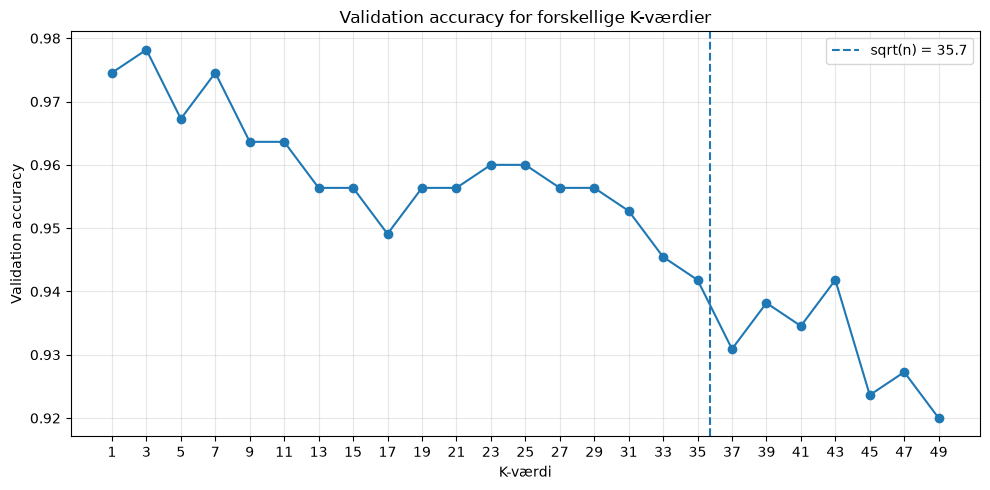

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(k_values, validation_accuracies, marker="o")
plt.axvline(sqrt_k, linestyle="--", label=f"sqrt(n) = {sqrt_k:.1f}")
plt.xlabel("K-værdi")
plt.ylabel("Validation accuracy")
plt.title("Validation accuracy for forskellige K-værdier")
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 10. Vælg K

Den højeste validation accuracy bliver fundet automatisk.

Vi vælger dog ikke nødvendigvis bare den højeste værdi. Hvis flere K-værdier ligger meget tæt, kan det give mening at vælge en lidt større K, fordi modellen så bruger flere naboer og bliver mindre følsom over for enkelte træningseksempler.

I vores resultat scorer **K=3** højest, men **K=7** ligger næsten lige så højt. Forskellen svarer kun til ét felt på validationdata. Derfor vælger vi **K=7** som et kompromis mellem høj accuracy og en lidt mindre følsom model.

In [ ]:
print(f"Bedste målte K-værdi: {best_k}")
print(f"Bedste validation accuracy: {best_accuracy:.2%}")

# Vi vælger K=7, selv om K=3 havde den højeste accuracy.
# Forskellen mellem K=3 og K=7 er kun ét korrekt felt på validationdata.
# K=7 bruger flere naboer og er derfor mindre følsom over for enkelte træningseksempler.
SELECTED_K = 7

selected_index = k_values.index(SELECTED_K)
selected_accuracy = validation_accuracies[selected_index]

print(f"Valgt K-værdi: {SELECTED_K}")
print(f"Validation accuracy for K={SELECTED_K}: {selected_accuracy:.2%}")
print(f"Forskel fra den bedste K-værdi: {(best_accuracy - selected_accuracy) * 100:.2f} procentpoint")

Bedste målte K-værdi: 3
Bedste validation accuracy: 97.82%
Valgt K-værdi: 3
Validation accuracy for K=3: 97.82%
Forskel fra den bedste K-værdi: 0.00 procentpoint


## 11. Træn den endelige model

Nu træner vi modellen med den K-værdi, vi har valgt.

Modellen trænes stadig kun på trainingdata.

In [ ]:
knn = KNeighborsClassifier(n_neighbors=SELECTED_K)
knn.fit(X_train_std, y_train)

print(f"Model trænet med K={SELECTED_K}.")

Model trænet med K=3.


## 12. Sammenlign training og validation

Vi sammenligner accuracy på training- og validationdata.

Hvis modellen klarer trainingdata meget bedre end validationdata, kan det være et tegn på overfitting.

In [ ]:
train_predictions = knn.predict(X_train_std)
val_predictions = knn.predict(X_val_std)

train_accuracy = accuracy_score(y_train, train_predictions)
val_accuracy = accuracy_score(y_val, val_predictions)

print(f"Training accuracy:   {train_accuracy:.2%}")
print(f"Validation accuracy: {val_accuracy:.2%}")
print(f"Forskel:              {(train_accuracy - val_accuracy) * 100:.2f} procentpoint")

Training accuracy:   98.12%
Validation accuracy: 97.82%
Forskel:              0.30 procentpoint


## 13. Endelig test

Til sidst tester vi modellen på testdata.

Testdata er ikke blevet brugt til at vælge K eller til at træne modellen.

In [ ]:
test_predictions = knn.predict(X_test_std)
test_accuracy = accuracy_score(y_test, test_predictions)

print(f"Endelig test accuracy: {test_accuracy:.2%}")

Endelig test accuracy: 96.33%


## 14. Confusion Matrix

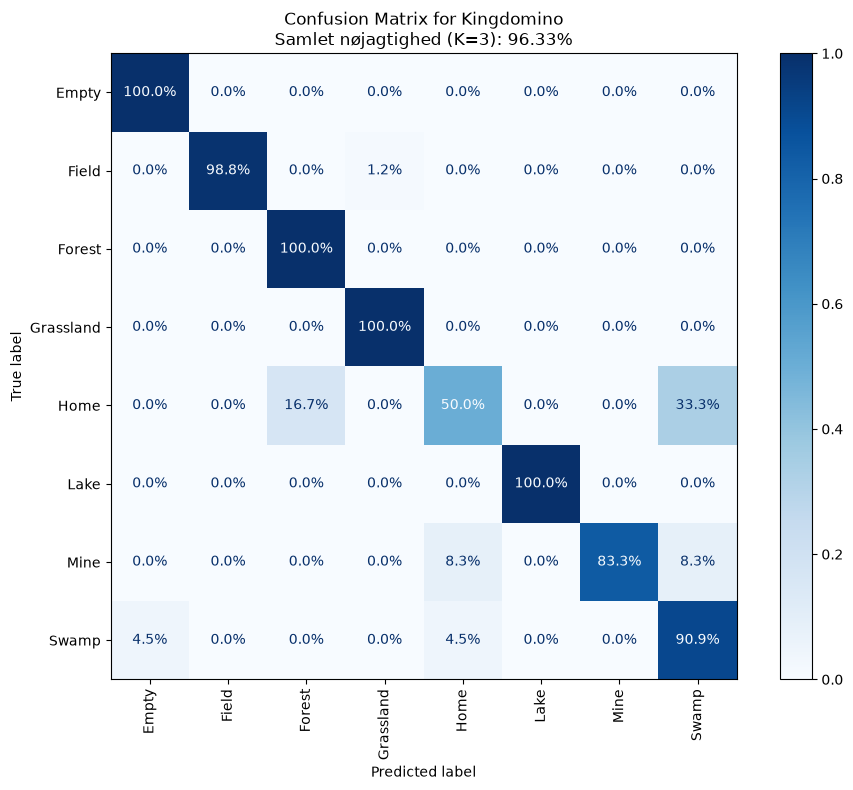

In [ ]:
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=knn.classes_,
    normalize="true"
)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=knn.classes_
)

disp.plot(
    cmap="Blues",
    xticks_rotation="vertical",
    ax=ax,
    values_format=".1%"
)

plt.title(
    f"Confusion Matrix for Kingdomino\n"
    f"Samlet nøjagtighed (K={SELECTED_K}): {test_accuracy:.2%}"
)

plt.tight_layout()
plt.show()

## Resultat

Notebooken viser nu hele forløbet fra rå billeder til den færdige model.

Det vigtigste er, at man kan se:

- hvordan data er delt op
- hvordan HSV-værdierne bliver lavet
- hvordan forskellige K-værdier klarer sig
- hvorfor vi vælger K=7
- hvordan modellen klarer sig på testdata
- hvilke terræntyper modellen oftest forveksler

In [6]:
DATASET_PATH = "dataset"
GROUND_TRUTH_PATH = "ground_truth.json"

TRAIN_BOARDS = ['1', '3', '4', '5', '7', '9', '10', '11', '12', '14', '18', '19', '20', '21', '23', '24', '25', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '44', '47', '49', '50', '52', '53', '54', '57', '58', '59', '60', '61', '63', '66', '67', '69', '71', '72', '74']

VALIDATION_BOARDS = ['2', '13', '15', '16', '43', '45', '46', '48', '51', '64', '73']

TEST_BOARDS = ['6', '8', '17', '22', '26', '27', '55', '56', '62', '65', '68', '70']